# 00 — Setup, data loading, evaluation and submission helpers

Shared building blocks for notebooks 03–07. The helper cells below are copied verbatim into later notebooks so each one runs standalone.

Rules to keep in mind:
- `tst` labels of sub-01..04 are **only** for validation; never fit on them or use them as templates.
- Submission rows must stay in the **original** order of `tst/sub-XX_tst.npy`.

In [1]:
# run once in the `krabiki` conda env (Python 3.11)
# %pip install -r requirements.txt

In [2]:
import os
import numpy as np
import matplotlib.pyplot as plt

In [3]:
TRAIN_DIR     = './trn'
TEST_DIR      = './tst'
TEST_STIM_DIR = './tst_stim'
SUBMIT_DIR    = './submissions'
SFREQ         = 500                     # Hz

SUBS         = [1, 2, 3, 4, 5, 6]
DEV_SUBS     = [1, 2, 3, 4]             # test labels available (validation only)
HELDOUT_SUBS = [5, 6]                   # test labels withheld -> submission
TEST_IDS     = np.arange(1001, 1103)    # the 102 candidate videos

## Data loading

In [4]:
def load_train(sub):
    """-> ids (n,), eeg (n, 17, 1500), sorted by video id."""
    z = np.load(f'{TRAIN_DIR}/sub-{sub:02d}_trn.npz')
    ids = np.array(sorted(z.files, key=int), dtype=int)
    eeg = np.stack([z[str(i)] for i in ids])
    return ids, eeg

def load_test(sub):
    """-> eeg (102, 17, 1500) in the ORIGINAL (shuffled) order. Never reorder for a submission."""
    return np.load(f'{TEST_DIR}/sub-{sub:02d}_tst.npy')

def load_test_labels(sub):
    """-> video id per test recording (102,), same order as load_test. Validation only."""
    assert sub in DEV_SUBS, f'test labels for sub-{sub:02d} are withheld'
    return np.load(f'{TEST_STIM_DIR}/sub-{sub:02d}_tst_stim.npy').astype(int)

## Ranking, evaluation and submission

Convention everywhere: `S` is a similarity matrix of shape `(n_recordings, n_videos)`, rows in the original recording order, column `j` = video `TEST_IDS[j]`. Higher = more likely.

In [5]:
def ranked_ids(S, video_ids=TEST_IDS):
    """(n_rec, n_vid) similarity -> (n_rec, n_vid) video IDs, most likely first."""
    return np.asarray(video_ids)[np.argsort(-S, axis=1)]

def topk(ranked, truth, ks=(1, 5)):
    """ranked: (n, n_vid) video IDs; truth: (n,) correct video id per row."""
    hits = ranked == np.asarray(truth)[:, None]
    assert hits.any(1).all(), 'some true videos are missing from the ranking'
    rank = hits.argmax(1) + 1
    out = {f'top{k}': float((rank <= k).mean()) for k in ks}
    out['median_rank'] = float(np.median(rank))
    return out

def check_submission(ranked):
    ranked = np.asarray(ranked)
    assert ranked.shape == (102, 102), ranked.shape
    assert np.issubdtype(ranked.dtype, np.integer), ranked.dtype
    assert (np.sort(ranked, 1) == TEST_IDS).all(), 'each row must be a permutation of 1001..1102'

def save_submission(ranked, sub, out_dir=SUBMIT_DIR):
    """ranked rows must be in the original tst order (no sorting by label)."""
    check_submission(ranked)
    os.makedirs(out_dir, exist_ok=True)
    path = f'{out_dir}/sub-{sub:02d}_ranked_candidate_list.npy'
    np.save(path, np.asarray(ranked, dtype=np.int64))
    return path

### Sanity checks of the helpers
A random similarity matrix should score at chance (~1% / ~4.9%), and an oracle matrix built from the labels should score 100%. The oracle only tests the evaluator's orientation; it is never used for modelling.

In [6]:
truth = load_test_labels(1)
rng = np.random.default_rng(0)

rand = np.mean([topk(ranked_ids(rng.standard_normal((102, 102))), truth)['top1'] for _ in range(200)])
print(f'random top-1 over 200 draws: {rand:.4f} (chance {1/102:.4f})')

S_oracle = (truth[:, None] == TEST_IDS[None, :]).astype(float)
ranked = ranked_ids(S_oracle)
check_submission(ranked)
print('oracle:', topk(ranked, truth))

# round trip through the submission file format
path = save_submission(ranked, 1, out_dir='./submissions_check')
print(path, topk(np.load(path), truth))

random top-1 over 200 draws: 0.0104 (chance 0.0098)
oracle: {'top1': 1.0, 'top5': 1.0, 'median_rank': 1.0}
./submissions_check/sub-01_ranked_candidate_list.npy {'top1': 1.0, 'top5': 1.0, 'median_rank': 1.0}


## Data overview

In [7]:
trn = {s: load_train(s) for s in SUBS}
tst = {s: load_test(s) for s in SUBS}

print('sub  n_train  train_std  test_std  ratio')
for s in SUBS:
    a, b = trn[s][1].std(), tst[s].std()
    print(f'{s:3d}  {len(trn[s][0]):7d}  {a:9.3f}  {b:8.3f}  {b/a:5.2f}')

shared = set.intersection(*(set(trn[s][0]) for s in SUBS))
print('train videos seen by all 6 subjects:', len(shared))

sub  n_train  train_std  test_std  ratio
  1      968      0.491     0.324   0.66
  2      972      0.460     0.311   0.68
  3      961      0.470     0.315   0.67
  4      947      0.464     0.288   0.62
  5      952      0.470     0.300   0.64
  6      850      0.461     0.287   0.62
train videos seen by all 6 subjects: 695


Train vs test ERP per subject. If the test recordings are averages over repeats, their ERP shape should match the train ERP while the single-trial noise (std) is lower.

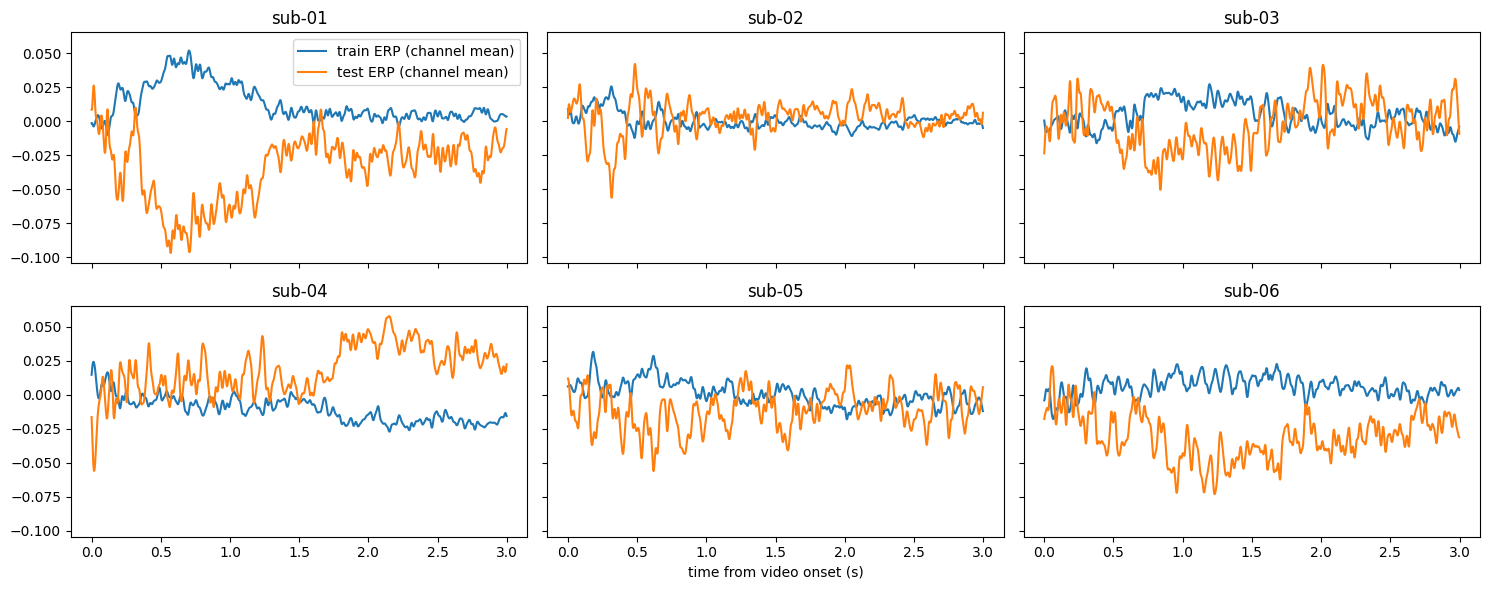

In [8]:
times = np.arange(1500) / SFREQ
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True, sharey=True)
for ax, s in zip(axes.flat, SUBS):
    ax.plot(times, trn[s][1].mean((0, 1)), label='train ERP (channel mean)')
    ax.plot(times, tst[s].mean((0, 1)), label='test ERP (channel mean)')
    ax.set_title(f'sub-{s:02d}')
axes[0, 0].legend(); axes[1, 1].set_xlabel('time from video onset (s)')
plt.tight_layout()

Text(0.5, 1.0, 'dashed = 1/sqrt(2), dotted = 1/sqrt(3) (expected if test averages 2 or 3 repeats)')

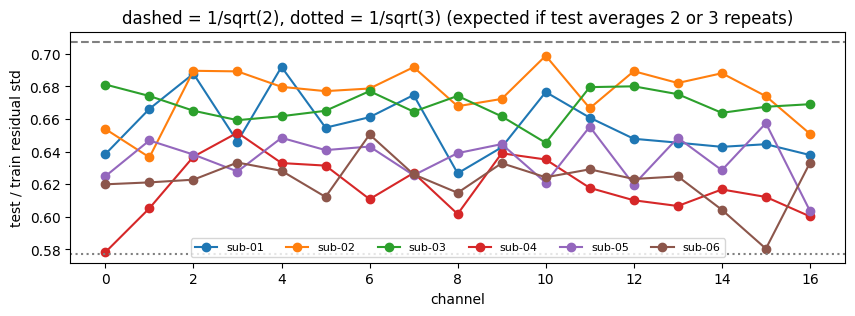

In [9]:
# per-channel noise: std across recordings after removing the ERP, test / train
fig, ax = plt.subplots(figsize=(10, 3))
for s in SUBS:
    r_trn = (trn[s][1] - trn[s][1].mean(0)).std((0, 2))
    r_tst = (tst[s] - tst[s].mean(0)).std((0, 2))
    ax.plot(r_tst / r_trn, marker='o', label=f'sub-{s:02d}')
ax.axhline(1/np.sqrt(2), ls='--', c='gray'); ax.axhline(1/np.sqrt(3), ls=':', c='gray')
ax.set_xlabel('channel'); ax.set_ylabel('test / train residual std'); ax.legend(ncol=6, fontsize=8)
ax.set_title('dashed = 1/sqrt(2), dotted = 1/sqrt(3) (expected if test averages 2 or 3 repeats)')